# UAV Energy Prediction — EDA, Cleaning, Feature Selection and Split



**Order:** Load → Overview → Define features → Outlier detection & removal → Flight-level EDA → Split → Missing value analysis → Feature filtering → Correlation → MI → Feature report → Select features → Target distribution → Correlation matrix → Save

## 1. Load Libraries and Dataset

In [44]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer

#Paths ──────────────────────────────────────────────────────────────────
DATA_PATH   = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_ml_ready_10hz_expanded.csv")
PROJECT_DIR = DATA_PATH.parents[1]
EDA_DIR     = PROJECT_DIR / "eda_outputs"
SPLIT_DIR   = PROJECT_DIR / "splits"
for d in [EDA_DIR, SPLIT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)
print("Flights:", df["log_id"].nunique())
print(df["dataset_label"].value_counts())
display(df.head())

Shape: (1019991, 378)
Flights: 172
dataset_label
normal      719371
abnormal    300620
Name: count, dtype: int64


,log_id,dataset_label,time_td,actuator_outputs__noutputs,actuator_outputs__output[0],actuator_outputs__output[1],actuator_outputs__output[2],actuator_outputs__output[3],actuator_outputs__output[4],actuator_outputs__output[5],...,vehicle_status__usb_connected,vehicle_status__open_drone_id_system_present,vehicle_status__open_drone_id_system_healthy,vehicle_status__parachute_system_present,vehicle_status__parachute_system_healthy,vehicle_status__avoidance_system_required,vehicle_status__avoidance_system_valid,vehicle_status__rc_calibration_in_progress,vehicle_status__calibration_enabled,vehicle_status__pre_flight_checks_pass
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Basic Dataset Overview

In [45]:
dataset_summary = pd.DataFrame({
    "Metric": ["Total rows","Total columns","Unique flight logs","Normal rows",
               "Abnormal rows","Normal flight logs","Abnormal flight logs","Sampling rate","Main target"],
    "Value": [df.shape[0], df.shape[1], df["log_id"].nunique(),
              df[df["dataset_label"]=="normal"].shape[0],
              df[df["dataset_label"]=="abnormal"].shape[0],
              df[df["dataset_label"]=="normal"]["log_id"].nunique(),
              df[df["dataset_label"]=="abnormal"]["log_id"].nunique(),
              "10 Hz", "target_energy_next_60s_wh"]
})
display(dataset_summary)
dataset_summary.to_csv(EDA_DIR / "01_dataset_summary.csv", index=False)

,Metric,Value
0,Total rows,1019991
1,Total columns,378
2,Unique flight logs,172
3,Normal rows,719371
4,Abnormal rows,300620
5,Normal flight logs,129
6,Abnormal flight logs,43
7,Sampling rate,10 Hz
8,Main target,target_energy_next_60s_wh


## 3. Define Target Column and Feature Lists

In [46]:
target_col = "target_energy_next_60s_wh"
non_feature_cols = ["log_id", "dataset_label", "time_td"]
leakage_cols     = ["target_energy_next_60s_wh", "future_cumulative_energy_wh", "future_remaining_60s", "target_remaining_drop_60s"]
cols_to_exclude  = non_feature_cols + leakage_cols

allowed_core_features = [
    "time_s",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__current_average_a",
    "battery_status__remaining",
    "battery_status__discharged_mah",
    "power_w",
    "energy_increment_wh",
    "cumulative_energy_wh"
]

print("Target:", target_col, "| exists:", target_col in df.columns)
print("\nCore features available:")
for col in allowed_core_features:
    print(f"  {col}: {col in df.columns}")

Target: target_energy_next_60s_wh | exists: True

Core features available:
  time_s: True
  battery_status__voltage_v: True
  battery_status__voltage_filtered_v: True
  battery_status__current_a: True
  battery_status__current_filtered_a: True
  battery_status__current_average_a: True
  battery_status__remaining: True
  battery_status__discharged_mah: True
  power_w: True
  energy_increment_wh: True
  cumulative_energy_wh: True


## 4. Outlier Detection and Removal (BEFORE split)

run before any splitting to ensure no bad flight leaks into any split.

In [47]:
# to find Which normal flights have suspiciously high target values
THRESHOLD = 20  #Wh: physically implausible for a normal 60s window

normal_df  = df[df["dataset_label"] == "normal"].copy()
high_energy = normal_df[normal_df[target_col] > THRESHOLD]

print(f"Rows with target > {THRESHOLD} Wh in NORMAL flights: {len(high_energy):,}")
print(f"  = {100 * len(high_energy) / len(normal_df):.3f}% of normal rows\n")

flight_summary = (
    high_energy.groupby("log_id")
    .agg(n_high_rows=(target_col, "count"),
         max_target=(target_col, "max"),
         mean_target=(target_col, "mean"),
         p95_target=(target_col, lambda x: x.quantile(0.95)))
    .sort_values("max_target", ascending=False)
    .reset_index()
)
print(f"Flights affected: {len(flight_summary)} / {normal_df['log_id'].nunique()} normal flights\n")
print(flight_summary.to_string(index=False))

Rows with target > 20 Wh in NORMAL flights: 22,062
  = 3.067% of normal rows

Flights affected: 1 / 129 normal flights

                              log_id  n_high_rows  max_target  mean_target  p95_target
e68d22d7-7b96-4767-a074-edfca1c7f78c        22062   66.087665    52.342273   55.178231


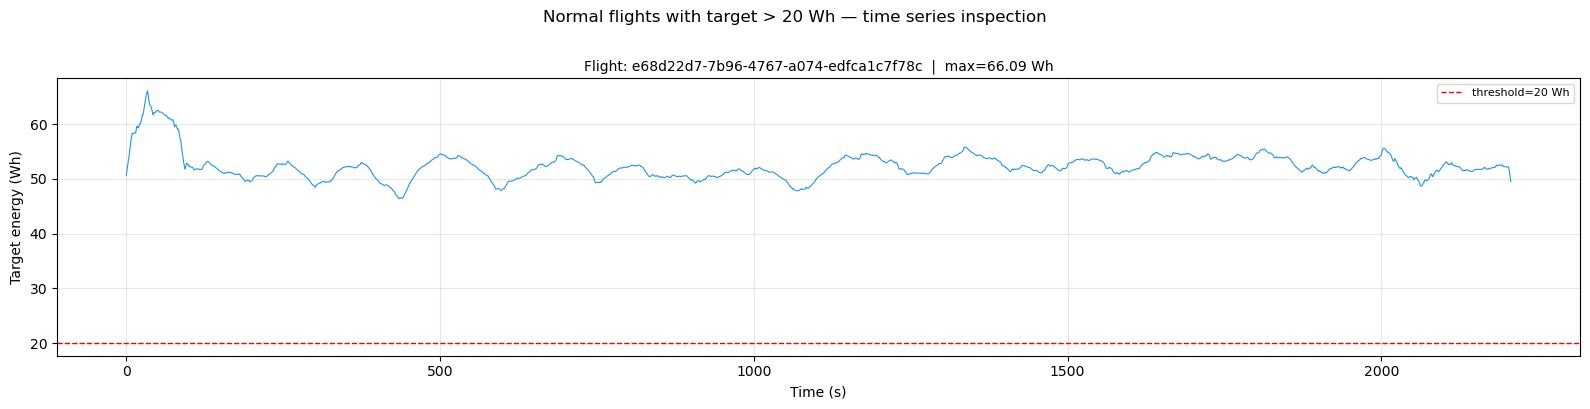

In [48]:
#Time-series plot of suspected flights
suspect_flights = flight_summary["log_id"].tolist()
n_plots = min(4, len(suspect_flights))

fig, axes = plt.subplots(n_plots, 1, figsize=(16, 4 * n_plots))
if n_plots == 1:
    axes = [axes]

for ax, fid in zip(axes, suspect_flights[:4]):
    fd = normal_df[normal_df["log_id"] == fid].sort_values("time_s")
    ax.plot(fd["time_s"], fd[target_col], linewidth=0.8, color="#2196F3")
    ax.axhline(THRESHOLD, color="red", linestyle="--", linewidth=1, label=f"threshold={THRESHOLD} Wh")
    ax.set_title(f"Flight: {fid}  |  max={fd[target_col].max():.2f} Wh", fontsize=10)
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Target energy (Wh)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.suptitle("Normal flights with target > 20 Wh — time series inspection", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_timeseries_suspect_flights.png", dpi=150, bbox_inches="tight")
plt.show()

possible reason for this high value include, real high power uav flight, different airframe or battery , since it is unsually high it will be flagged as potential outlier

IQR Method
  Q1=0.2779  Q3=3.0706  IQR=2.7926
  Outlier upper bound (Q3+3xIQR): 11.4485 Wh
  Rows above threshold: 22,062 (3.067%)

Z-score Method (|z|>3)
  Rows flagged: 22,062 (3.067%)
  Min flagged value: 46.4028 Wh

Percentile Breakdown
  p90: 3.6068 Wh
  p95: 5.3111 Wh
  p99: 53.0762 Wh
  p99.5: 54.0081 Wh
  p99.9: 58.3473 Wh
  p100: 66.0877 Wh


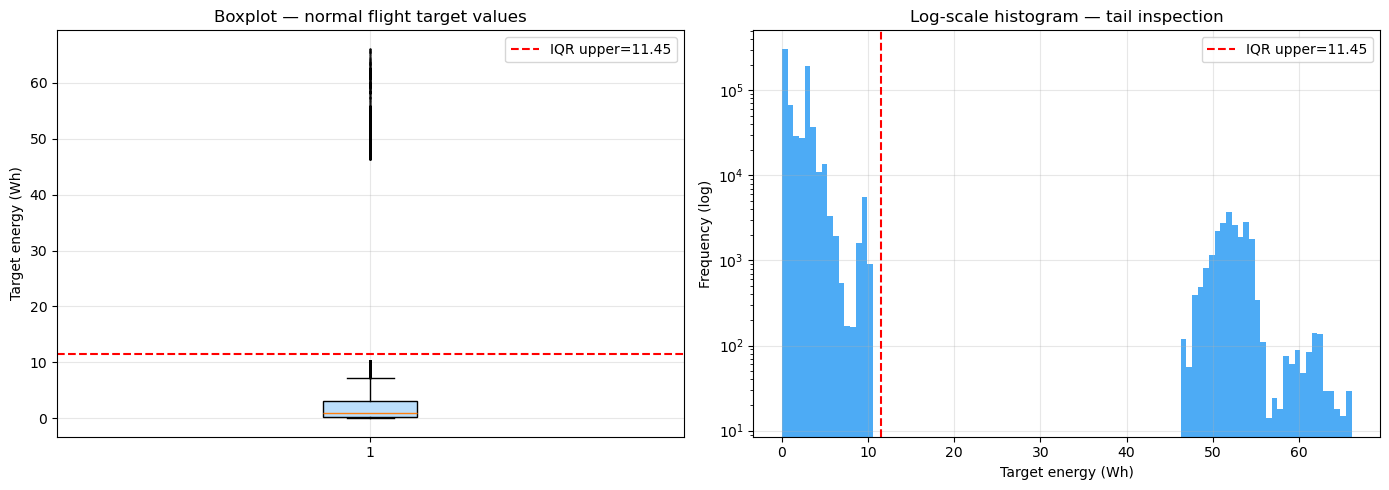

In [49]:
#IQR + Z-score statistical outlier test

target_vals = normal_df[target_col].dropna()
Q1, Q3 = target_vals.quantile(0.25), target_vals.quantile(0.75)
IQR = Q3 - Q1
iqr_upper = Q3 + 3 * IQR
z_scores = np.abs(stats.zscore(target_vals))

print("IQR Method")
print(f"  Q1={Q1:.4f}  Q3={Q3:.4f}  IQR={IQR:.4f}")
print(f"  Outlier upper bound (Q3+3xIQR): {iqr_upper:.4f} Wh")
print(f"  Rows above threshold: {(target_vals > iqr_upper).sum():,} ({100*(target_vals>iqr_upper).mean():.3f}%)")
print("\nZ-score Method (|z|>3)")
print(f"  Rows flagged: {(z_scores>3).sum():,} ({100*(z_scores>3).mean():.3f}%)")
if (z_scores>3).any():
    print(f"  Min flagged value: {target_vals[z_scores>3].min():.4f} Wh")
print("\nPercentile Breakdown")
for p in [90, 95, 99, 99.5, 99.9, 100]:
    print(f"  p{p}: {np.percentile(target_vals, p):.4f} Wh")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.boxplot(target_vals, vert=True, patch_artist=True,
            boxprops=dict(facecolor="#BBDEFB"),
            flierprops=dict(marker=".", markersize=1, alpha=0.3))
ax1.axhline(iqr_upper, color="red", linestyle="--", label=f"IQR upper={iqr_upper:.2f}")
ax1.set_title("Boxplot — normal flight target values")
ax1.set_ylabel("Target energy (Wh)"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.hist(target_vals, bins=100, color="#2196F3", alpha=0.8, edgecolor="none", log=True)
ax2.axvline(iqr_upper, color="red", linestyle="--", label=f"IQR upper={iqr_upper:.2f}")
ax2.set_title("Log-scale histogram — tail inspection")
ax2.set_xlabel("Target energy (Wh)"); ax2.set_ylabel("Frequency (log)"); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_iqr_zscore_test.png", dpi=150)
plt.show()

Top 20 high-target rows with their power_w values:
                              log_id  time_s   power_w  energy_increment_wh  cumulative_energy_wh  target_energy_next_60s_wh
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.6 3593.2422             0.099812             23.708082                  66.087665
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.7 3593.2422             0.099812             23.807894                  66.071539
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.8 3387.1223             0.094087             23.901981                  66.061138
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.5 3226.6917             0.089630             23.608269                  66.060095
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.9 3387.1223             0.094087             23.996067                  66.026597
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.4 3226.6917             0.089630             23.518639                  66.022343
e68d22d7-7b96-4767-a074-edfca1c7f78c    34.0 3477.0989             0.09658

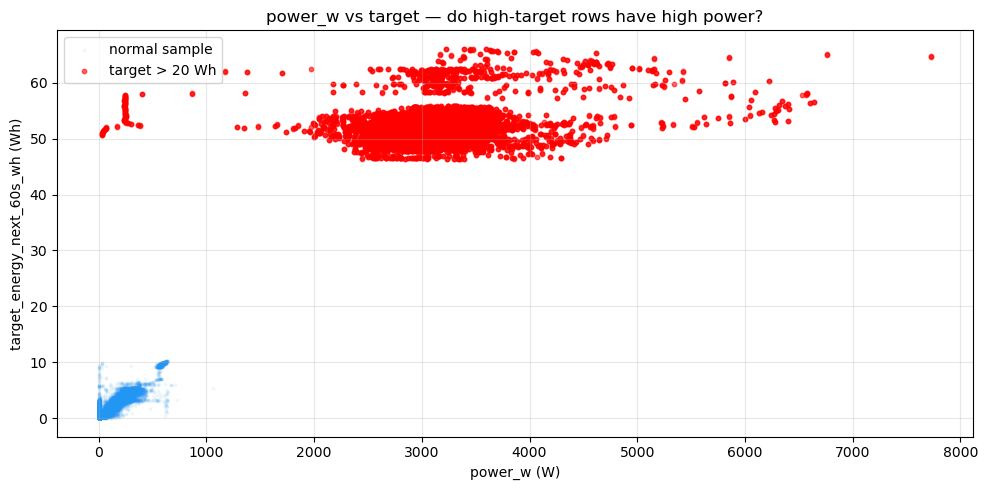

In [50]:
#physics sanity check
high_rows = normal_df[normal_df[target_col] > THRESHOLD][
    ["log_id", "time_s", "power_w", "energy_increment_wh", "cumulative_energy_wh", target_col]
].sort_values(target_col, ascending=False)

print("Top 20 high-target rows with their power_w values:")
print(high_rows.head(20).to_string(index=False))
print(f"\n  mean power_w (outlier rows)   : {high_rows['power_w'].mean():.2f} W") #Average power where target is suspiciously high
print(f"  max  power_w (outlier rows)   : {high_rows['power_w'].max():.2f} W") #Highest power in those suspicious rows
print(f"  Normal fleet mean power_w     : {normal_df['power_w'].mean():.2f} W") #Average power across all normal rows
print(f"  Normal fleet 99 percentile  power_w     : {normal_df['power_w'].quantile(0.99):.2f} W") #99th percentile power in normal data

fig, ax = plt.subplots(figsize=(10, 5))
sample = normal_df.sample(min(50000, len(normal_df)), random_state=42)
ax.scatter(sample["power_w"], sample[target_col], alpha=0.05, s=3, color="#2196F3", label="normal sample")
ax.scatter(high_rows["power_w"], high_rows[target_col], alpha=0.6, s=10, color="red", label=f"target > {THRESHOLD} Wh")
ax.set_xlabel("power_w (W)"); ax.set_ylabel("target_energy_next_60s_wh (Wh)")
ax.set_title("power_w vs target — do high-target rows have high power?")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_power_vs_target.png", dpi=150)
plt.show()

16 times higher than normal flights

In [51]:
before_shape = df.shape
before_flights = df["log_id"].nunique()

suspect_flights = flight_summary["log_id"].dropna().unique().tolist()
df = df[~df["log_id"].isin(suspect_flights)].copy()

print("Before shape:", before_shape)
print("After shape:", df.shape)
print("Flights removed:", before_flights - df["log_id"].nunique())

Before shape: (1019991, 378)
After shape: (997929, 378)
Flights removed: 1


During EDA, one normal-labelled flight produced extremely high next-60-second energy targets, with values above 60 Wh. A physics sanity check showed that these rows also had very high instantaneous power, with an average power of approximately 3133 W compared with the normal fleet mean of 193 W. This suggests that the high target values were physically consistent with the measured power draw, but the flight behaved very differently from the majority of normal flights. Therefore, it was flagged as a high-energy outlier rather than treated as a typical normal flight.

## 5. Flight-Level EDA (run on clean df)

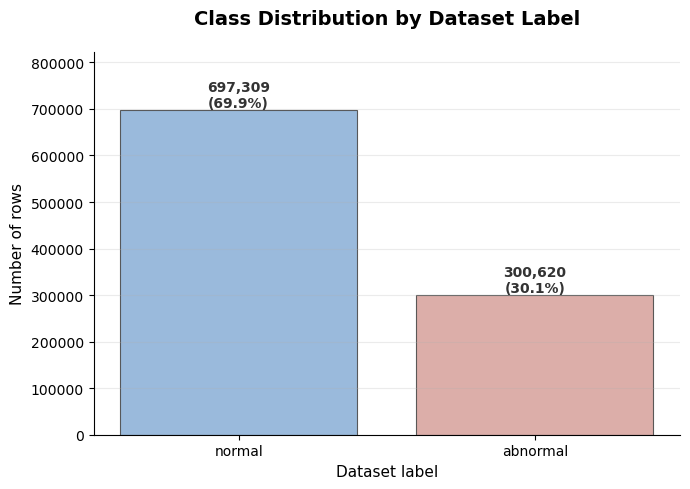

dataset_label
normal      697309
abnormal    300620
Name: count, dtype: int64


In [71]:
#Class imbalance bar chart

label_counts = df["dataset_label"].value_counts()
total_rows = label_counts.sum()
percentages = (label_counts / total_rows) * 100


soft_colors = ["#8FB3D9", "#D9A5A0"] 

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    label_counts.index,
    label_counts.values,
    color=soft_colors,
    edgecolor="#4A4A4A",
    linewidth=0.8,
    alpha=0.9
)

for bar, count, pct in zip(bars, label_counts.values, percentages.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#333333"
    )

ax.set_title("Class Distribution by Dataset Label", fontsize=14, fontweight="bold", pad=20)
ax.set_xlabel("Dataset label", fontsize=11)
ax.set_ylabel("Number of rows", fontsize=11)

ax.set_ylim(0, label_counts.max() * 1.18)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print(label_counts)

Flight duration (seconds) by label:
               count   mean    std    min    25%    50%    75%     max
dataset_label                                                         
abnormal        43.0  700.3  418.4  249.6  431.4  570.6  814.2  1924.3
normal         128.0  546.2  304.7  249.2  375.6  434.8  662.6  2391.3


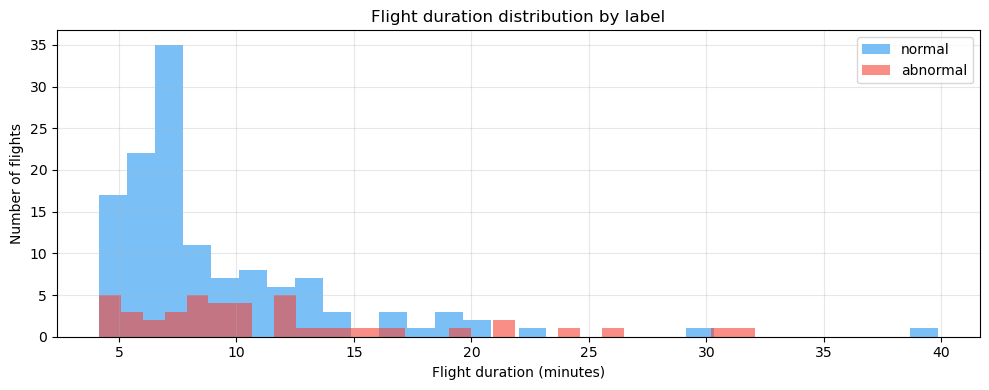

In [72]:
#Flight duration distribution per label
flight_durations = (
    df.groupby(["log_id","dataset_label"])["time_s"]
    .max().reset_index()
    .rename(columns={"time_s":"duration_s"})
)
flight_durations["duration_min"] = flight_durations["duration_s"] / 60

print("Flight duration (seconds) by label:")
print(flight_durations.groupby("dataset_label")["duration_s"].describe().round(1))

fig, ax = plt.subplots(figsize=(10, 4))
for label, color in [("normal","#2196F3"),("abnormal","#F44336")]:
    vals = flight_durations[flight_durations["dataset_label"]==label]["duration_min"]
    ax.hist(vals, bins=30, alpha=0.6, label=label, color=color, edgecolor="none")
ax.set_xlabel("Flight duration (minutes)"); ax.set_ylabel("Number of flights")
ax.set_title("Flight duration distribution by label")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "eda_flight_duration_distribution.png", dpi=150)
plt.show()

# 6. Sampling Rate Validation for 60-Second Energy Prediction

This check is important because the 60-second prediction target assumes that 600 rows represent exactly 60 seconds, so the data must have consistent 0.1-second intervals at 10 Hz.

In [ ]:
#Sampling Rate Validation for 60-Second Energy Prediction
expected_gap = 0.1
allowed_gap = 0.15

df_sorted = df.sort_values(["log_id", "time_s"]).copy()

df_sorted["time_gap"] = df_sorted.groupby("log_id")["time_s"].diff()

time_gaps = df_sorted["time_gap"].dropna()

gap_summary = pd.DataFrame({
    "Check": [
        "Expected gap for 10 Hz data",
        "Average observed gap",
        "Median observed gap",
        "Smallest observed gap",
        "Largest observed gap",
        "Total time gaps checked",
        "Number of gaps above allowed limit",
        "Percentage of large gaps"
    ],
    "Result": [
        expected_gap,
        round(time_gaps.mean(), 6),
        round(time_gaps.median(), 6),
        round(time_gaps.min(), 6),
        round(time_gaps.max(), 6),
        len(time_gaps),
        (time_gaps > allowed_gap).sum(),
        round((time_gaps > allowed_gap).mean() * 100, 4)
    ]
})

display(gap_summary)

large_gaps = (time_gaps > allowed_gap).sum()

if large_gaps == 0:
    print("Conclusion: The dataset is consistent with 10 Hz sampling.")
    print("This supports the use of 600 rows as a 60-second prediction window.")
else:
    print("Conclusion: Some larger time gaps were found.")
    print("These gaps should be reviewed before using 600 rows as a fixed 60-second window.")

,Check,Result
0,Expected gap for 10 Hz data,0.100000
1,Average observed gap,0.100245
2,Median observed gap,0.100000
3,Smallest observed gap,0.100000
4,Largest observed gap,6.700000
5,Total time gaps checked,997758.000000
6,Number of gaps above allowed limit,411.000000
7,Percentage of large gaps,0.041200


Result: Some larger time gaps were found.
These gaps should be reviewed before using 600 rows as a fixed 60-second window.


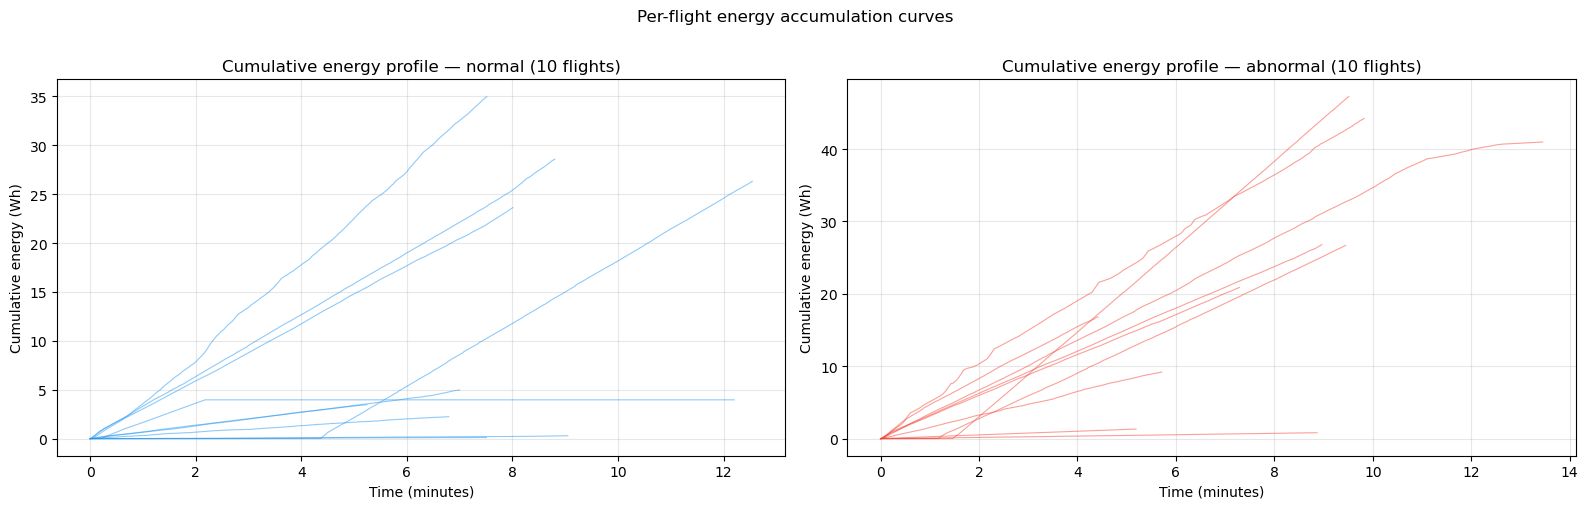

In [55]:
# ── 5d: Per-flight cumulative energy profile overlay ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, label, color in zip(axes, ["normal","abnormal"], ["#2196F3","#F44336"]):
    flight_ids = df[df["dataset_label"]==label]["log_id"].unique()
    rng = np.random.RandomState(42)
    sample_ids = rng.choice(flight_ids, size=min(10, len(flight_ids)), replace=False)
    for fid in sample_ids:
        fd = df[df["log_id"]==fid].sort_values("time_s")
        ax.plot(fd["time_s"]/60, fd["cumulative_energy_wh"],
                alpha=0.5, linewidth=0.8, color=color)
    ax.set_title(f"Cumulative energy profile — {label} (10 flights)")
    ax.set_xlabel("Time (minutes)"); ax.set_ylabel("Cumulative energy (Wh)"); ax.grid(alpha=0.3)
plt.suptitle("Per-flight energy accumulation curves", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(EDA_DIR / "eda_energy_profile_overlay.png", dpi=150, bbox_inches="tight")
plt.show()

In [56]:
# ── 5e: Rolling window boundary check ────────────────────────────────────
# Last 600 rows of each flight (60s x 10Hz) should have NaN target
boundary_nan_rate = df.groupby("log_id").tail(600)[target_col].isna().mean()
print(f"NaN rate in last 600 rows of each flight: {boundary_nan_rate:.4f}")
if boundary_nan_rate > 0.95:
    print("CHECK PASS: Rolling window boundary is clean — no cross-flight leakage detected.")
else:
    print("WARNING: target is non-NaN at flight tails — check cross-flight leakage in preprocessing!")

NaN rate in last 600 rows of each flight: 0.0000


## 6. Train / Val / Test Split (on clean df)

In [57]:
unique_flights = df[["log_id","dataset_label"]].drop_duplicates()

train_flights, temp_flights = train_test_split(
    unique_flights, test_size=0.30, random_state=42,
    stratify=unique_flights["dataset_label"]
)
val_flights, test_flights = train_test_split(
    temp_flights, test_size=0.50, random_state=42,
    stratify=temp_flights["dataset_label"]
)

train_df = df[df["log_id"].isin(train_flights["log_id"])].copy()
val_df   = df[df["log_id"].isin(val_flights["log_id"])].copy()
test_df  = df[df["log_id"].isin(test_flights["log_id"])].copy()

print(f"Train     : {train_df.shape}  | flights: {train_df['log_id'].nunique()}")
print(f"Validation: {val_df.shape}    | flights: {val_df['log_id'].nunique()}")
print(f"Test      : {test_df.shape}   | flights: {test_df['log_id'].nunique()}")

print("\nLabel balance per split:")
for name, split in [("Train",train_df),("Val",val_df),("Test",test_df)]:
    dist = split["dataset_label"].value_counts(normalize=True).round(3)
    print(f"  {name}: {dict(dist)}")

Train     : (649057, 378)  | flights: 119
Validation: (177538, 378)    | flights: 26
Test      : (171334, 378)   | flights: 26

Label balance per split:
  Train: {'normal': np.float64(0.711), 'abnormal': np.float64(0.289)}
  Val: {'normal': np.float64(0.719), 'abnormal': np.float64(0.281)}
  Test: {'normal': np.float64(0.63), 'abnormal': np.float64(0.37)}


## 7. Missing Value Report and Heatmap (train_df only)

In [58]:
missing_report = pd.DataFrame({
    "column": train_df.columns,
    "missing_count_train": train_df.isna().sum().values,
    "missing_percent_train": train_df.isna().mean().values * 100,
    "data_type": train_df.dtypes.astype(str).values,
    "unique_values_train": train_df.nunique(dropna=True).values
}).sort_values("missing_percent_train", ascending=False).reset_index(drop=True)

print(f"Columns 100% missing : {(missing_report['missing_percent_train']==100).sum()}")
print(f"Columns >80% missing : {(missing_report['missing_percent_train']>80).sum()}")
print(f"Columns 0% missing   : {(missing_report['missing_percent_train']==0).sum()}")
display(missing_report.head(50))
missing_report.to_csv(EDA_DIR / "03_missing_report_train.csv", index=False)

Columns 100% missing : 247
Columns >80% missing : 342
Columns 0% missing   : 21


,column,missing_count_train,missing_percent_train,data_type,unique_values_train
0,vehicle_status__pre_flight_checks_pass,649057,100.0,float64,0
1,vehicle_gps_position__selected_rtcm_instance,649057,100.0,float64,0
2,vehicle_air_data__time_td,649057,100.0,float64,0
3,vehicle_air_data__rho,649057,100.0,float64,0
4,vehicle_air_data__baro_pressure_pa,649057,100.0,float64,0
5,vehicle_air_data__baro_temp_celcius,649057,100.0,float64,0
6,vehicle_air_data__baro_alt_meter,649057,100.0,float64,0
7,vehicle_gps_position__spoofing_state,649057,100.0,float64,0
8,vehicle_gps_position__rtcm_crc_failed,649057,100.0,float64,0
9,vehicle_attitude__delta_q_reset[1],649057,100.0,float64,0


Columns with any missingness: 357 / 378


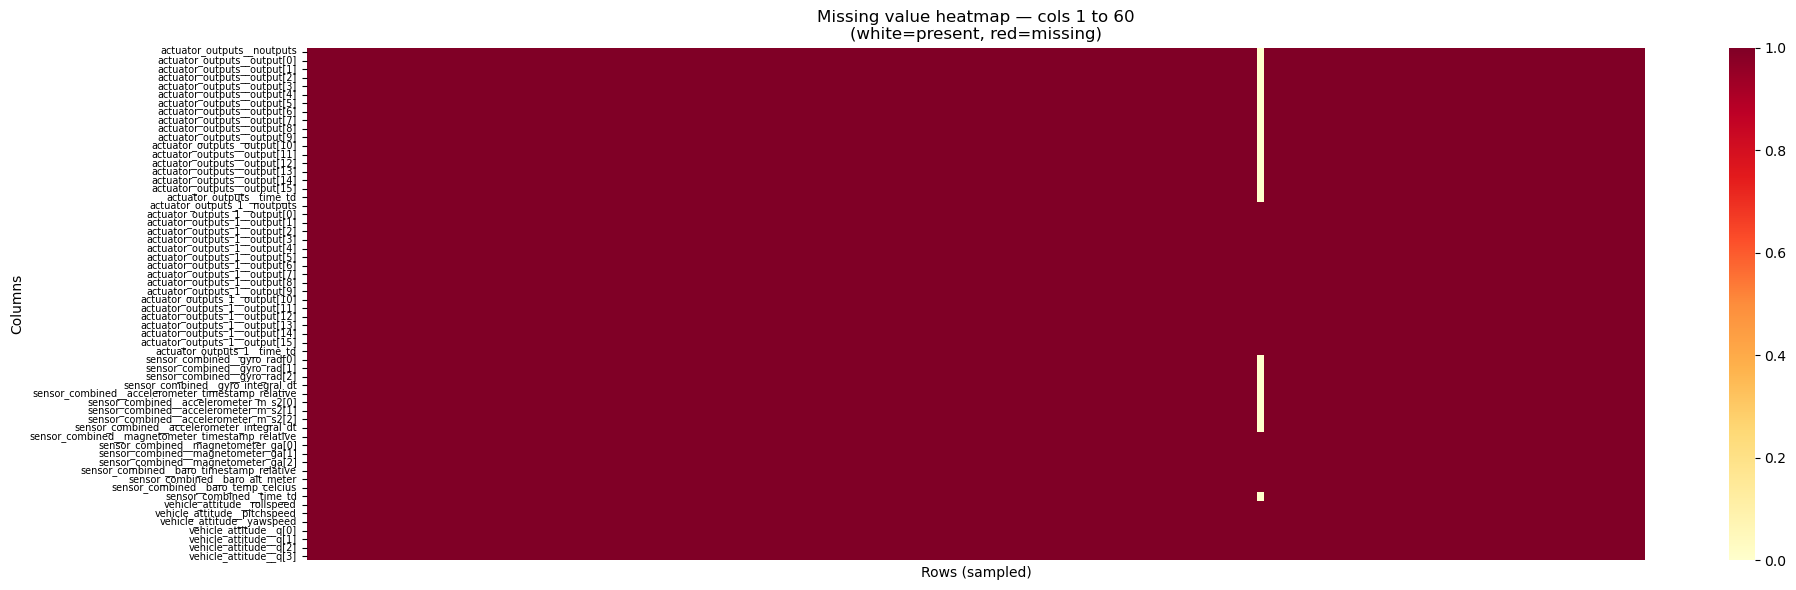

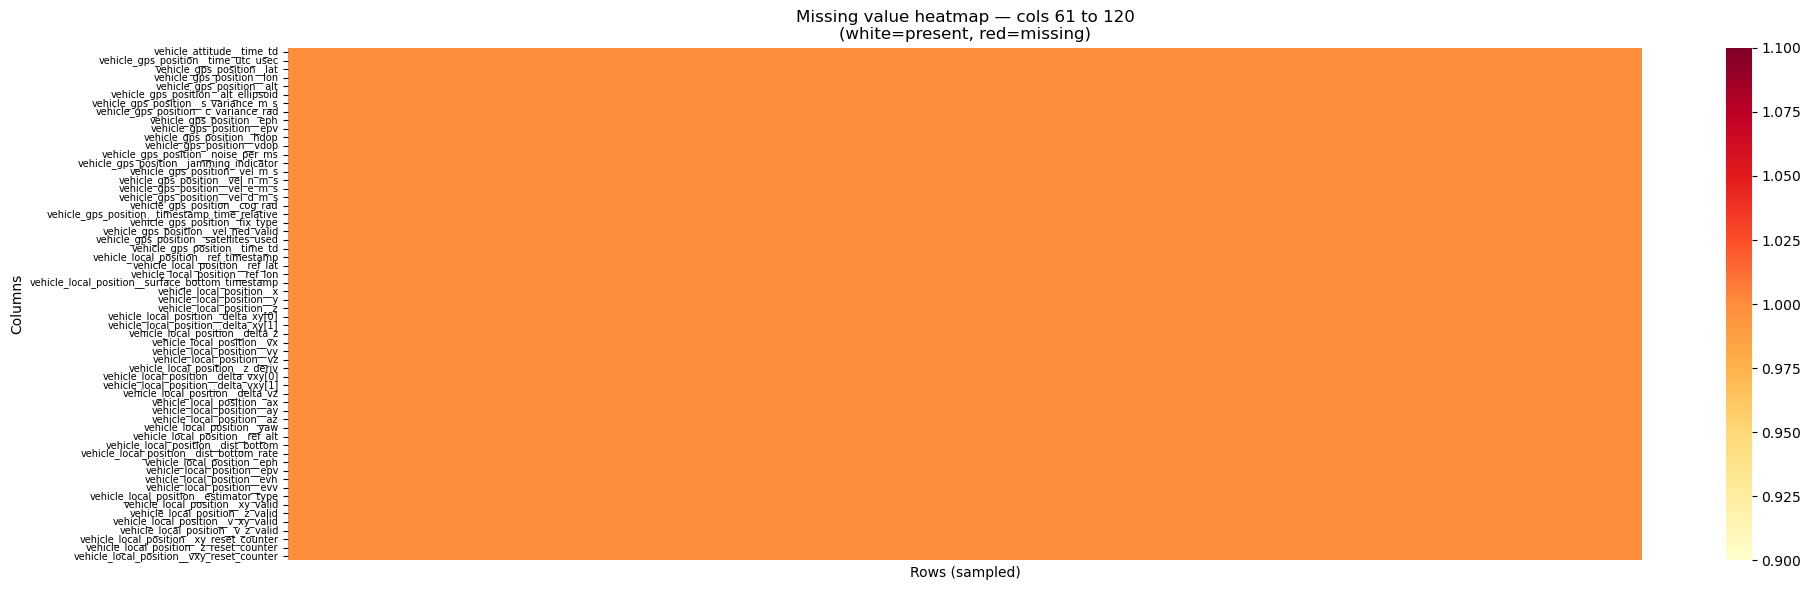

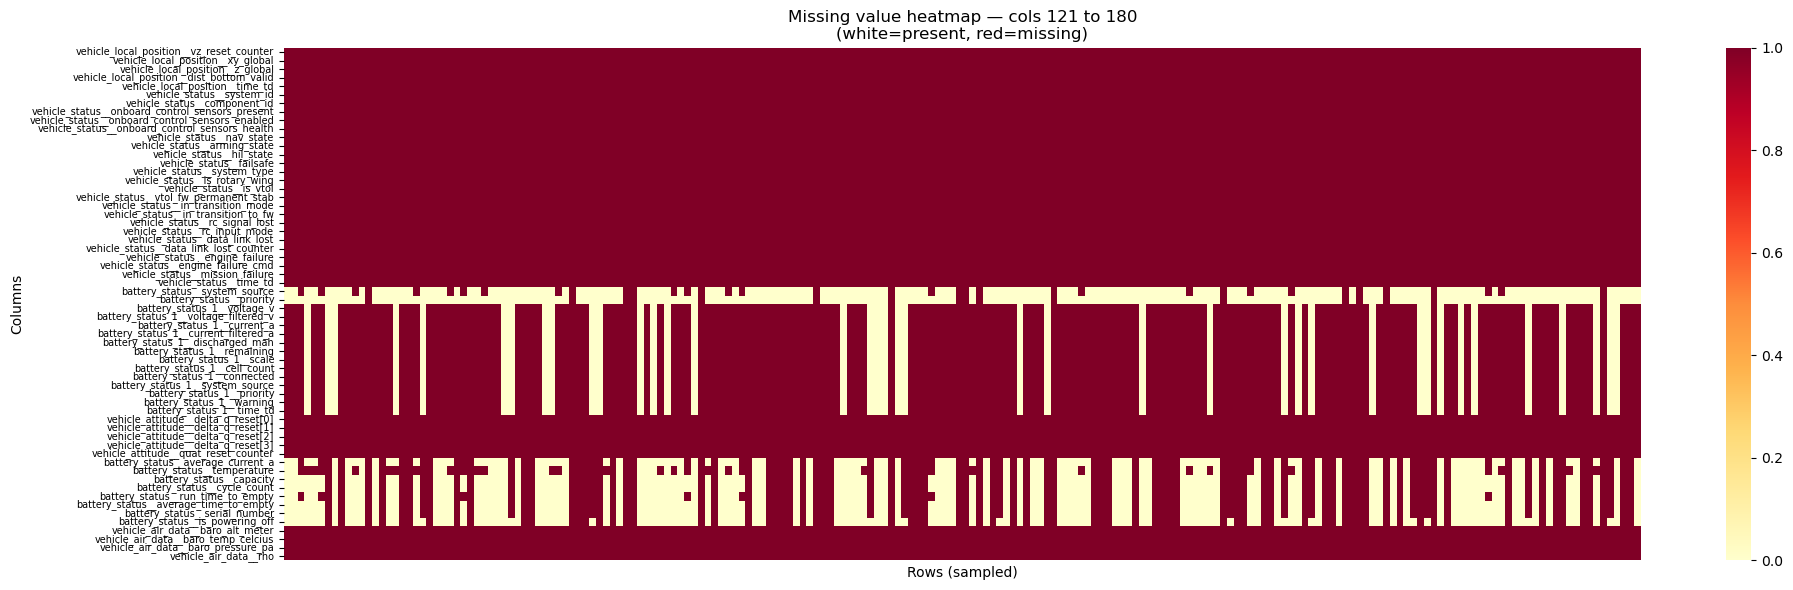

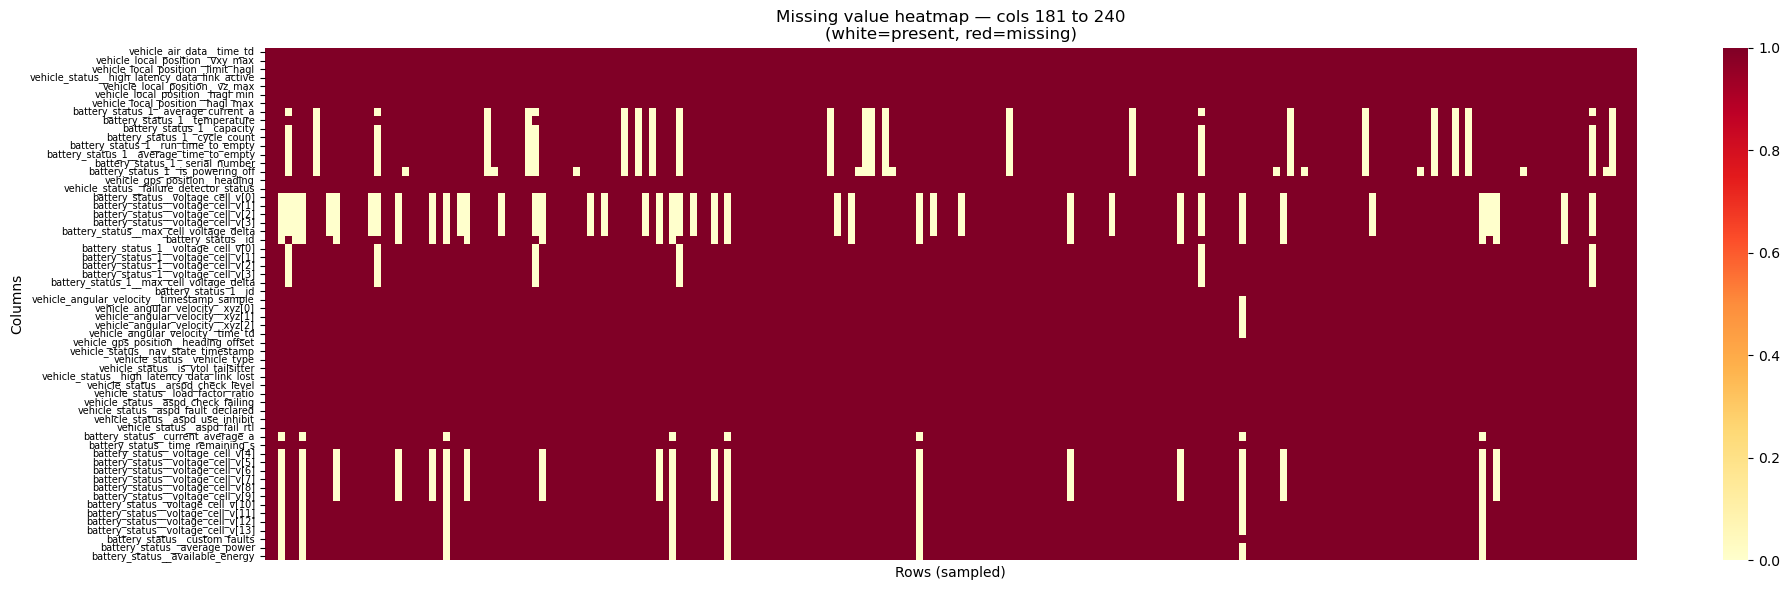

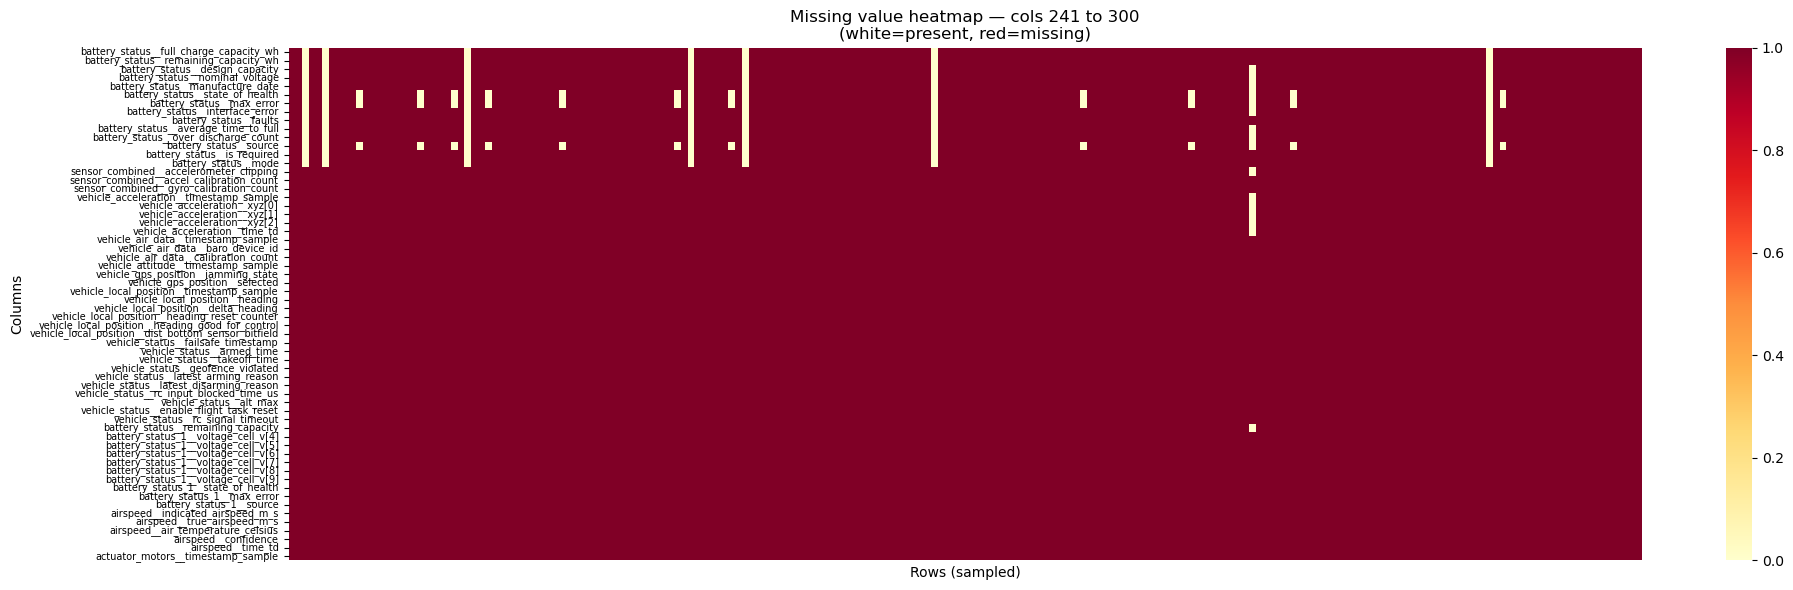

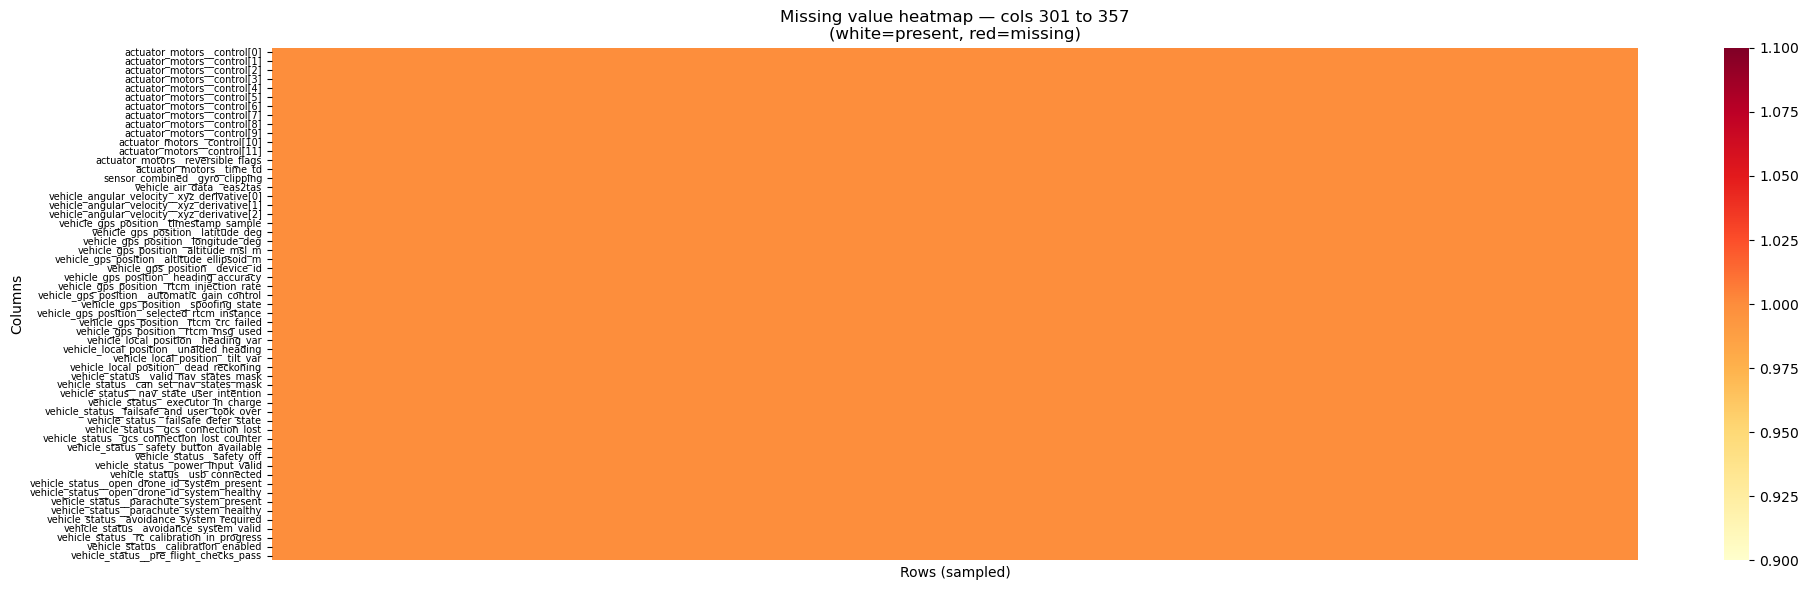

In [59]:
# ── Missing value heatmap (chunked) ──────────────────────────────────────
SAMPLE_N = 50000
sample_df = train_df.sample(n=SAMPLE_N, random_state=42)
miss_pct = sample_df.isnull().mean() * 100
cols_with_missing = miss_pct[miss_pct > 0].index.tolist()
print(f"Columns with any missingness: {len(cols_with_missing)} / {len(train_df.columns)}")

def plot_missing_heatmap(df_subset, title_suffix):
    fig, ax = plt.subplots(figsize=(20, 6))
    step = max(1, len(df_subset) // 200)
    sns.heatmap(df_subset.iloc[::step].isnull().astype(int).T,
                ax=ax, cbar=True, cmap="YlOrRd",
                yticklabels=True, xticklabels=False, linewidths=0)
    ax.set_title(f"Missing value heatmap — {title_suffix}\n(white=present, red=missing)", fontsize=12)
    ax.set_xlabel("Rows (sampled)"); ax.set_ylabel("Columns")
    ax.tick_params(axis="y", labelsize=7)
    plt.tight_layout()
    safe = title_suffix.replace(" ","_").replace("–","")
    plt.savefig(EDA_DIR / f"missing_heatmap_{safe}.png", dpi=150)
    plt.show()

CHUNK = 60
for i in range(0, len(cols_with_missing), CHUNK):
    chunk = cols_with_missing[i:i+CHUNK]
    plot_missing_heatmap(sample_df[chunk], f"cols {i+1} to {min(i+CHUNK, len(cols_with_missing))}")

## 8. Feature Candidate Filtering

In [60]:
MISSING_THRESHOLD = 80
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()

candidate_features = []
for col in numeric_cols:
    if col in cols_to_exclude or col == target_col:
        continue
    if train_df[col].isna().mean() * 100 >= MISSING_THRESHOLD:
        continue
    if train_df[col].nunique(dropna=True) <= 1:
        continue
    candidate_features.append(col)

print(f"Candidate features after filtering: {len(candidate_features)}")
print(candidate_features)

Candidate features after filtering: 18
['battery_status__voltage_v', 'battery_status__voltage_filtered_v', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__cell_count', 'battery_status__warning', 'time_s', 'power_w', 'energy_increment_wh', 'cumulative_energy_wh', 'battery_status__system_source', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]']


## 9. Correlation with Target (train_df only)

In [61]:
correlation_rows = []
for col in candidate_features:
    temp = train_df[[col, target_col]].dropna()
    if len(temp) < 100:
        continue
    pearson  = temp[col].corr(temp[target_col], method="pearson")
    spearman = temp[col].corr(temp[target_col], method="spearman")
    correlation_rows.append({
        "column": col,
        "pearson_corr": pearson,
        "abs_pearson_corr": abs(pearson) if pd.notna(pearson) else np.nan,
        "spearman_corr": spearman,
        "abs_spearman_corr": abs(spearman) if pd.notna(spearman) else np.nan
    })

correlation_report = (pd.DataFrame(correlation_rows)
    .sort_values("abs_pearson_corr", ascending=False)
    .reset_index(drop=True))

display(correlation_report.head(40))
correlation_report.to_csv(EDA_DIR / "04_correlation_with_target.csv", index=False)

,column,pearson_corr,abs_pearson_corr,spearman_corr,abs_spearman_corr
0,power_w,0.959335,0.959335,0.923307,0.923307
1,energy_increment_wh,0.959335,0.959335,0.923307,0.923307
2,battery_status__current_filtered_a,0.758801,0.758801,0.807673,0.807673
3,battery_status__current_a,0.745779,0.745779,0.814108,0.814108
4,cumulative_energy_wh,0.716668,0.716668,0.771033,0.771033
5,battery_status__discharged_mah,0.673903,0.673903,0.651871,0.651871
6,battery_status__cell_count,0.660903,0.660903,0.334062,0.334062
7,battery_status__voltage_filtered_v,0.615065,0.615065,0.219865,0.219865
8,battery_status__voltage_v,0.611771,0.611771,0.231589,0.231589
9,time_s,0.246877,0.246877,0.238213,0.238213


## 10. Mutual Information (train_df only)

In [62]:
MI_SAMPLE = 100_000
mi_sample = train_df[candidate_features + [target_col]].dropna(subset=[target_col]).copy()
if len(mi_sample) > MI_SAMPLE:
    mi_sample = mi_sample.sample(n=MI_SAMPLE, random_state=42)

X_mi = SimpleImputer(strategy="median").fit_transform(mi_sample[candidate_features])
y_mi = mi_sample[target_col]
mi_scores = mutual_info_regression(X_mi, y_mi, random_state=42)

mi_report = (pd.DataFrame({"column": candidate_features, "mutual_information_score": mi_scores})
    .sort_values("mutual_information_score", ascending=False)
    .reset_index(drop=True))

display(mi_report.head(40))
mi_report.to_csv(EDA_DIR / "05_mutual_information.csv", index=False)

,column,mutual_information_score
0,cumulative_energy_wh,2.574539
1,battery_status__discharged_mah,2.544971
2,battery_status__current_filtered_a,2.233762
3,battery_status__voltage_filtered_v,2.067356
4,battery_status__voltage_v,1.779396
5,energy_increment_wh,1.756684
6,power_w,1.756530
7,battery_status__current_a,1.661139
8,time_s,1.338734
9,battery_status__remaining,1.301704


## 11. Combined Feature Selection Report

In [63]:
feature_report = missing_report[["column","missing_percent_train","data_type","unique_values_train"]].copy()
feature_report = feature_report.merge(correlation_report, on="column", how="left")
feature_report = feature_report.merge(mi_report, on="column", how="left")
feature_report["is_candidate_feature"] = feature_report["column"].isin(candidate_features)
feature_report["is_core_feature"]      = feature_report["column"].isin(allowed_core_features)
feature_report["cols_to_exclude"]      = feature_report["column"].isin(cols_to_exclude)

feature_report["selection_reason"] = "Not selected"
feature_report.loc[feature_report["cols_to_exclude"],          "selection_reason"] = "Removed: identifier/label/leakage"
feature_report.loc[feature_report["missing_percent_train"]>=80, "selection_reason"] = "Removed: >80% missing"
feature_report.loc[feature_report["unique_values_train"]<=1,   "selection_reason"] = "Removed: constant column"
feature_report.loc[feature_report["is_candidate_feature"],      "selection_reason"] = "Candidate: passed quality checks"
feature_report.loc[
    feature_report["is_core_feature"] & feature_report["is_candidate_feature"],
    "selection_reason"
] = "Selected: domain-relevant battery/energy feature"

display(feature_report.sort_values(
    ["is_candidate_feature","mutual_information_score"], ascending=[False,False]).head(60))

,column,missing_percent_train,data_type,unique_values_train,pearson_corr,abs_pearson_corr,spearman_corr,abs_spearman_corr,mutual_information_score,is_candidate_feature,is_core_feature,cols_to_exclude,selection_reason
373,cumulative_energy_wh,0.000000,float64,524432,0.716668,0.716668,0.771033,0.771033,2.574539,True,True,False,Selected: domain-relevant battery/energy feature
360,battery_status__discharged_mah,0.000000,float64,131690,0.673903,0.673903,0.651871,0.651871,2.544971,True,True,False,Selected: domain-relevant battery/energy feature
357,battery_status__current_filtered_a,0.000000,float64,136162,0.758801,0.758801,0.807673,0.807673,2.233762,True,True,False,Selected: domain-relevant battery/energy feature
363,battery_status__voltage_filtered_v,0.000000,float64,139086,0.615065,0.615065,0.219865,0.219865,2.067356,True,True,False,Selected: domain-relevant battery/energy feature
361,battery_status__voltage_v,0.000000,float64,13736,0.611771,0.611771,0.231589,0.231589,1.779396,True,True,False,Selected: domain-relevant battery/energy feature
372,energy_increment_wh,0.000000,float64,106392,0.959335,0.959335,0.923307,0.923307,1.756684,True,True,False,Selected: domain-relevant battery/energy feature
367,power_w,0.000000,float64,106392,0.959335,0.959335,0.923307,0.923307,1.756530,True,True,False,Selected: domain-relevant battery/energy feature
362,battery_status__current_a,0.000000,float64,8746,0.745779,0.745779,0.814108,0.814108,1.661139,True,True,False,Selected: domain-relevant battery/energy feature
370,time_s,0.000000,float64,23914,0.246877,0.246877,0.238213,0.238213,1.338734,True,True,False,Selected: domain-relevant battery/energy feature
359,battery_status__remaining,0.000000,float64,119769,0.016253,0.016253,-0.061540,0.061540,1.301704,True,True,False,Selected: domain-relevant battery/energy feature


## 12. Select Final Feature Columns

In [64]:
top_corr_features = correlation_report.head(30)["column"].tolist()
top_mi_features   = mi_report.head(30)["column"].tolist()
valid_core        = [c for c in allowed_core_features if c in candidate_features]

final_feature_cols = sorted(set(valid_core + top_corr_features + top_mi_features))

print(f"Final feature count: {len(final_feature_cols)}")
for col in final_feature_cols:
    print(f"  {col}")

Final feature count: 18
  battery_status__cell_count
  battery_status__current_a
  battery_status__current_filtered_a
  battery_status__discharged_mah
  battery_status__remaining
  battery_status__scale
  battery_status__system_source
  battery_status__voltage_cell_v[0]
  battery_status__voltage_cell_v[1]
  battery_status__voltage_cell_v[2]
  battery_status__voltage_cell_v[3]
  battery_status__voltage_filtered_v
  battery_status__voltage_v
  battery_status__warning
  cumulative_energy_wh
  energy_increment_wh
  power_w
  time_s


## 13. Target Distribution (on clean df — post outlier removal)

normal: n=697,309  median=0.823  p99=9.223  max=10.309
abnormal: n=300,620  median=2.776  p99=24.630  max=27.502


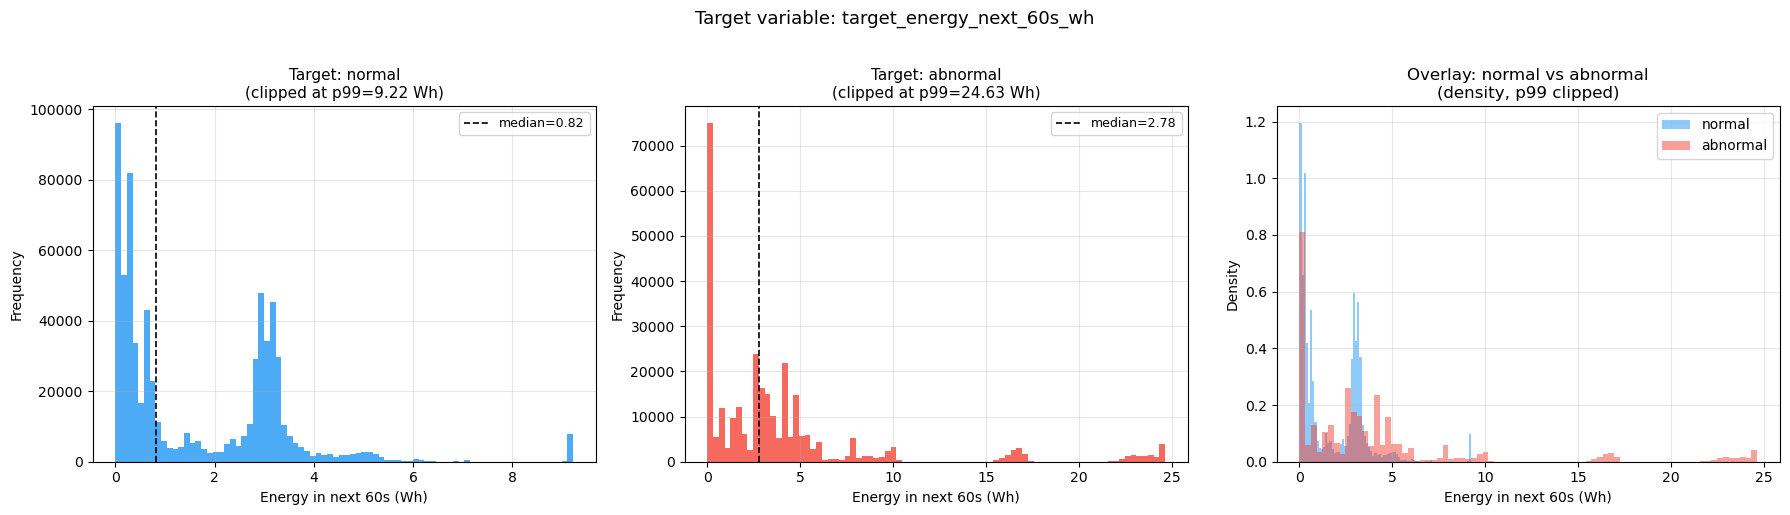

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {"normal":"#2196F3", "abnormal":"#F44336"}

for ax, label in zip(axes[:2], ["normal","abnormal"]):
    subset = df[df["dataset_label"]==label][target_col].dropna()
    p99    = np.percentile(subset, 99)
    clipped = subset.clip(upper=p99)
    print(f"{label}: n={len(subset):,}  median={subset.median():.3f}  p99={p99:.3f}  max={subset.max():.3f}")
    ax.hist(clipped, bins=80, color=colors[label], alpha=0.8, edgecolor="none")
    ax.axvline(subset.median(), color="black", linestyle="--", linewidth=1.2,
               label=f"median={subset.median():.2f}")
    ax.set_title(f"Target: {label}\n(clipped at p99={p99:.2f} Wh)", fontsize=11)
    ax.set_xlabel("Energy in next 60s (Wh)"); ax.set_ylabel("Frequency")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[2]
for label in ["normal","abnormal"]:
    subset = df[df["dataset_label"]==label][target_col].dropna()
    p99    = np.percentile(subset, 99)
    ax.hist(subset.clip(upper=p99), bins=80, alpha=0.5, label=label,
            color=colors[label], edgecolor="none", density=True)
ax.set_title("Overlay: normal vs abnormal\n(density, p99 clipped)")
ax.set_xlabel("Energy in next 60s (Wh)"); ax.set_ylabel("Density")
ax.legend(); ax.grid(alpha=0.3)

plt.suptitle("Target variable: target_energy_next_60s_wh", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(EDA_DIR / "target_distribution_clean.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Correlation Matrix — Final Features + Target

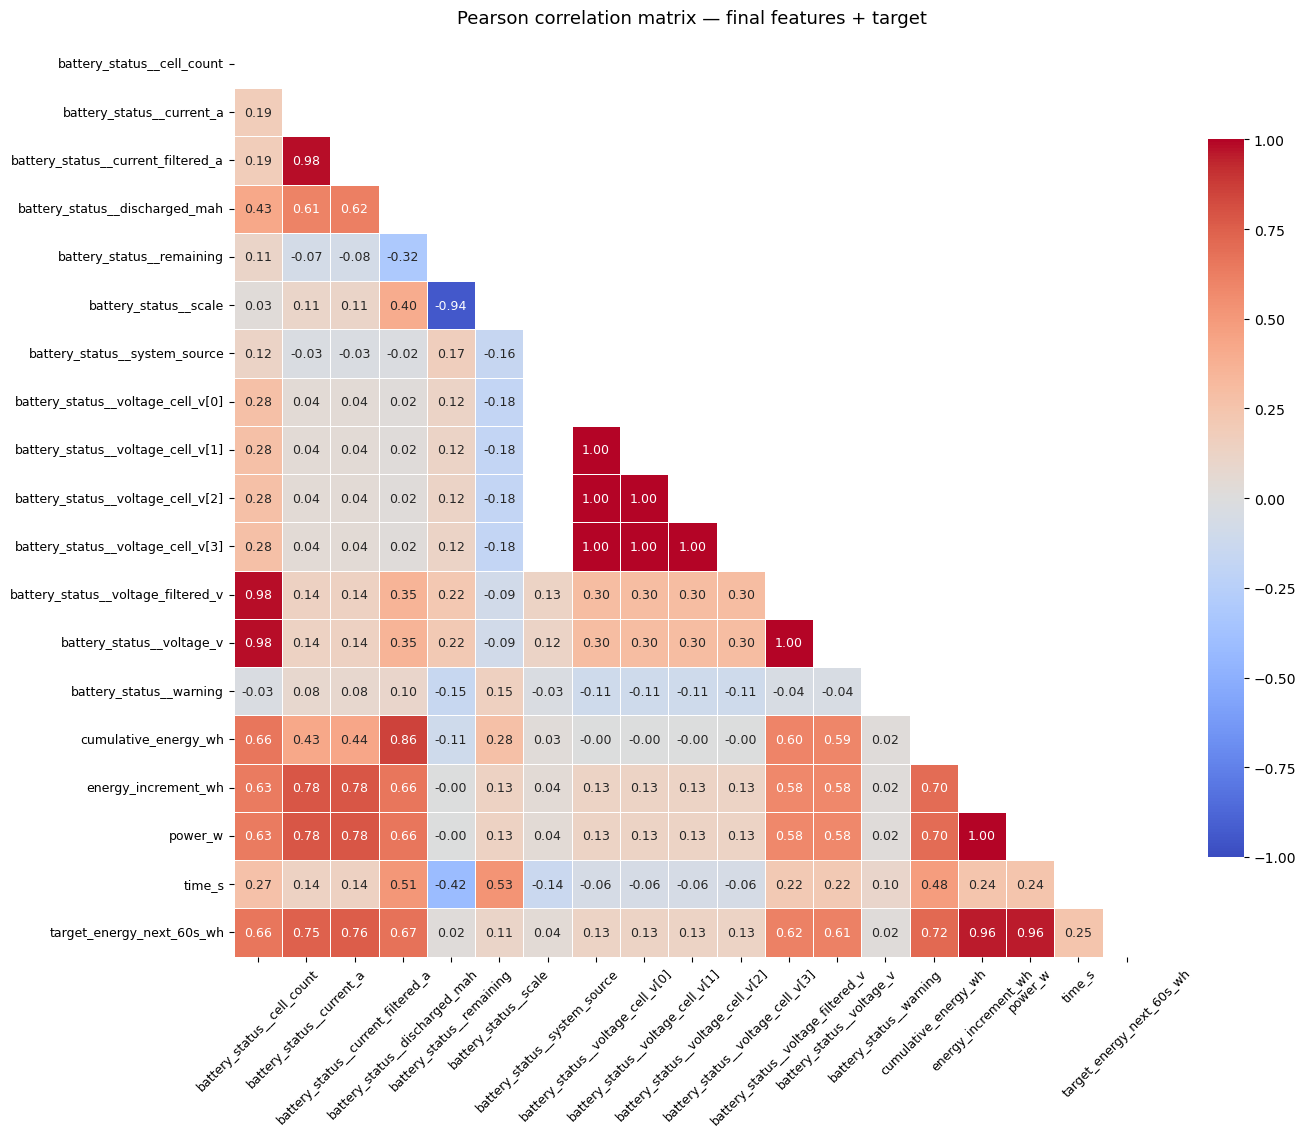


Top correlations with target:
power_w                               0.959335
energy_increment_wh                   0.959335
battery_status__current_filtered_a    0.758801
battery_status__current_a             0.745779
cumulative_energy_wh                  0.716668
battery_status__discharged_mah        0.673903
battery_status__cell_count            0.660903
battery_status__voltage_filtered_v    0.615065
battery_status__voltage_v             0.611771
time_s                                0.246877
battery_status__voltage_cell_v[3]     0.127189
battery_status__voltage_cell_v[1]     0.127189
battery_status__voltage_cell_v[0]     0.127189
battery_status__voltage_cell_v[2]     0.127189
battery_status__scale                 0.114448
battery_status__system_source         0.042175
battery_status__warning               0.016833
battery_status__remaining             0.016253
Name: target_energy_next_60s_wh, dtype: float64


In [66]:
corr_cols   = final_feature_cols + [target_col]
corr_matrix = train_df[corr_cols].corr()
mask        = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr_matrix, ax=ax, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink":0.7}, annot_kws={"size":9})
ax.set_title("Pearson correlation matrix — final features + target", fontsize=13, pad=12)
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0,  labelsize=9)
plt.tight_layout()
plt.savefig(EDA_DIR / "correlation_matrix_final_features.png", dpi=150)
plt.show()

print("\nTop correlations with target:")
print(corr_matrix[target_col].drop(target_col).abs().sort_values(ascending=False))

## 15. Final Model-Ready Datasets

In [67]:
final_model_cols = ["log_id","dataset_label"] + final_feature_cols + [target_col]
train_model_df   = train_df[final_model_cols].copy()
val_model_df     = val_df[final_model_cols].copy()
test_model_df    = test_df[final_model_cols].copy()

print("Train :", train_model_df.shape)
print("Val   :", val_model_df.shape)
print("Test  :", test_model_df.shape)
display(train_model_df.head())

Train : (649057, 21)
Val   : (177538, 21)
Test  : (171334, 21)


,log_id,dataset_label,battery_status__cell_count,battery_status__current_a,battery_status__current_filtered_a,battery_status__discharged_mah,battery_status__remaining,battery_status__scale,battery_status__system_source,battery_status__voltage_cell_v[0],...,battery_status__voltage_cell_v[2],battery_status__voltage_cell_v[3],battery_status__voltage_filtered_v,battery_status__voltage_v,battery_status__warning,cumulative_energy_wh,energy_increment_wh,power_w,time_s,target_energy_next_60s_wh
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,1.0,NaN,...,NaN,NaN,11.758164,11.763942,0.0,0.000000,0.000000,0.000000,0.0,0.001262
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,1.0,NaN,...,NaN,NaN,11.758164,11.763942,0.0,0.000000,0.000000,0.000000,0.1,0.001262
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,1.0,NaN,...,NaN,NaN,11.758164,11.763942,0.0,0.000000,0.000000,0.000000,0.2,0.001262
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.00000,0.124580,0.010021,0.833148,1.031092,1.0,NaN,...,NaN,NaN,11.758164,11.763942,0.0,0.000000,0.000000,0.000000,0.3,0.001262
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,3.0,0.46793,0.088367,0.016040,0.784237,1.040576,1.0,NaN,...,NaN,NaN,11.754977,11.730804,0.0,0.000152,0.000152,5.489191,0.4,0.001109


## 16. Save All Reports and Datasets

In [68]:
# ── Feature reports ───────────────────────────────────────────────────────
feature_report.to_excel(EDA_DIR / "feature_selection_evidence_report.xlsx", index=False)
correlation_report.to_csv(EDA_DIR / "correlation_with_target_report.csv", index=False)
mi_report.to_csv(EDA_DIR / "mutual_information_report.csv", index=False)

# ── Model-ready splits ────────────────────────────────────────────────────
train_model_df.to_csv(SPLIT_DIR / "train_model_ready_selected_features.csv", index=False)
val_model_df.to_csv(SPLIT_DIR   / "val_model_ready_selected_features.csv",   index=False)
test_model_df.to_csv(SPLIT_DIR  / "test_model_ready_selected_features.csv",  index=False)

print("Saved reports to :", EDA_DIR)
print("Saved splits to  :", SPLIT_DIR)

Saved reports to : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/eda_outputs
Saved splits to  : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/splits
